In [2]:
import pandas as pd

In [3]:
from sklearn.datasets import load_wine
winedata=load_wine()

In [4]:
type(winedata)

sklearn.utils._bunch.Bunch

In [5]:
df = pd.DataFrame( winedata.data, columns=winedata.feature_names, index=winedata.target )

In [6]:
df

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
0,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
0,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
0,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
0,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0
2,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0
2,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0
2,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0


In [7]:
df.index.unique()

Index([0, 1, 2], dtype='int64')

Thus there are three different values
This dataset represents different parameters for three different kinds of wine.

In [8]:
import matplotlib.pyplot as plt

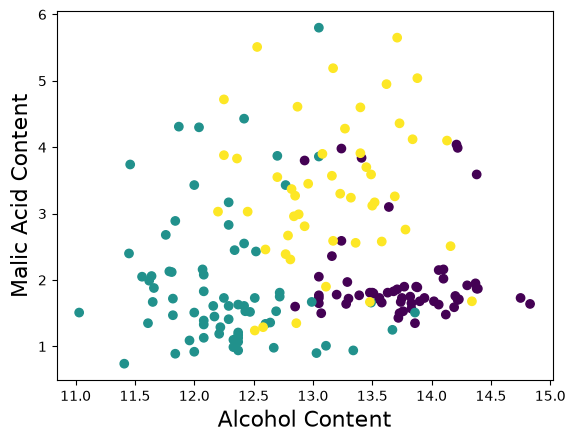

In [9]:
plt.scatter(df['alcohol'],df['malic_acid'],c=df.index)
plt.xlabel('Alcohol Content',fontsize=16)
plt.ylabel('Malic Acid Content',fontsize=16)
plt.show()

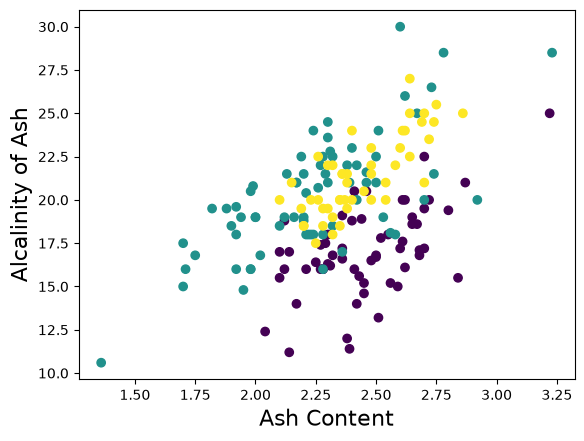

In [10]:
plt.scatter(df['ash'],df['alcalinity_of_ash'],c=df.index)
plt.xlabel('Ash Content',fontsize=16)
plt.ylabel('Alcalinity of Ash',fontsize=16)
plt.show()

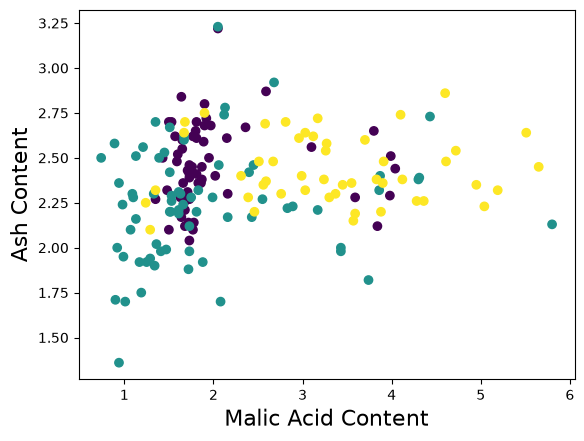

In [11]:
plt.scatter(df['malic_acid'],df['ash'],c=df.index)
plt.xlabel('Malic Acid Content',fontsize=16)
plt.ylabel('Ash Content',fontsize=16)
plt.show()

A better way would be to apply dimensionality reduction and see if things get better. 

In [12]:
from sklearn.decomposition import PCA

In [13]:
pca=PCA()
pca_1=pca.fit(df)

We have now achieved dimensionality reduction. We can explore the components following dimensionality reductions as shown below

In [14]:
pca_1.components_

array([[ 1.65926472e-03, -6.81015556e-04,  1.94905742e-04,
        -4.67130058e-03,  1.78680075e-02,  9.89829680e-04,
         1.56728830e-03, -1.23086662e-04,  6.00607792e-04,
         2.32714319e-03,  1.71380037e-04,  7.04931645e-04,
         9.99822937e-01],
       [ 1.20340617e-03,  2.15498184e-03,  4.59369254e-03,
         2.64503930e-02,  9.99344186e-01,  8.77962152e-04,
        -5.18507284e-05, -1.35447892e-03,  5.00440040e-03,
         1.51003530e-02, -7.62673115e-04, -3.49536431e-03,
        -1.77738095e-02],
       [ 1.68738094e-02,  1.22003373e-01,  5.19874304e-02,
         9.38593003e-01, -2.97802484e-02, -4.04846439e-02,
        -8.54433387e-02,  1.35107797e-02, -2.46593824e-02,
         2.91398464e-01, -2.59776624e-02, -7.03239693e-02,
         4.52868159e-03],
       [ 1.41446778e-01,  1.60389543e-01, -9.77280992e-03,
        -3.30965260e-01, -5.39375605e-03, -7.45846556e-02,
        -1.69086724e-01,  1.08055610e-02, -5.01209524e-02,
         8.78893693e-01, -6.00349446e

In [15]:
pca_1.components_.shape

(13, 13)

We would certainly like to know the distribution of % variance explained across these 13 components

In [16]:
pca_1.explained_variance_ratio_

array([9.98091230e-01, 1.73591562e-03, 9.49589576e-05, 5.02173562e-05,
       1.23636847e-05, 8.46213034e-06, 2.80681456e-06, 1.52308053e-06,
       1.12783044e-06, 7.21415811e-07, 3.78060267e-07, 2.12013755e-07,
       8.25392788e-08])

These values are not that illuminating. Let us plot these proportions to understand them better.

In [17]:
import seaborn as sns

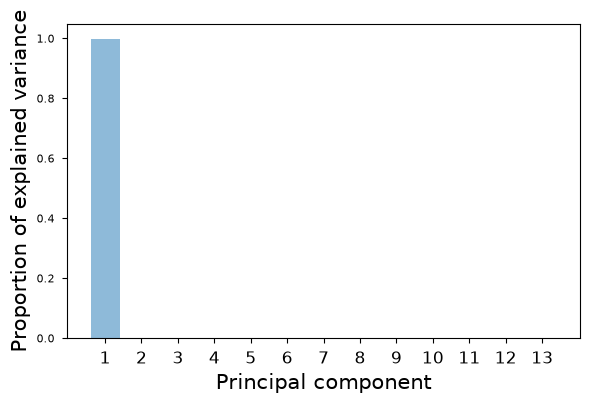

In [20]:
with plt.style.context('seaborn-v0_8-paper'):
    plt.figure(figsize=(6,4))

    plt.bar(range(13), pca_1.explained_variance_ratio_,alpha=0.5,align='center')
    plt.ylabel('Proportion of explained variance', fontsize=15)
    plt.xlabel('Principal component',fontsize=15)
    plt.xticks([0,1,2,3,4,5,6,7,8,9,10,11,12],["1","2","3","4","5","6","7","8","9","10","11","12","13"],fontsize=12)
    plt.tight_layout()

It seems that the first principle components explains all the variance.
We can check if this is true as follows.

In [22]:
wine_exp_var=pd.DataFrame(pca_1.explained_variance_ratio_,columns=["Proportion of variance explained"])

In [23]:
wine_exp_var.round(decimals=3)

,Proportion of variance explained
0,0.998
1,0.002
2,0.000
3,0.000
4,0.000
5,0.000
6,0.000
7,0.000
8,0.000
9,0.000


Indeed PC1 explains almost 100% variance


Let us know try to project our data on the PC space.

In [24]:
pca_2=pca.transform(df)
pca_2

array([[ 3.18562979e+02,  2.14921307e+01, -3.13073470e+00, ...,
         8.87340044e-02, -3.85475626e-02,  8.02644337e-02],
       [ 3.03097420e+02, -5.36471768e+00, -6.82283550e+00, ...,
         3.97781862e-02, -5.71915771e-02,  1.35927465e-02],
       [ 4.38061133e+02, -6.53730945e+00,  1.11322298e+00, ...,
         2.37770027e-01, -4.87978751e-02, -3.54081623e-02],
       ...,
       [ 8.84580737e+01,  1.87762846e+01,  2.23757651e+00, ...,
        -2.23049341e-01,  9.60485020e-02,  3.61748954e-02],
       [ 9.34562419e+01,  1.86708191e+01,  1.78839152e+00, ...,
        -3.04078323e-02, -5.20893107e-02,  1.32759078e-01],
       [-1.86943190e+02, -2.13330803e-01,  5.63050984e+00, ...,
         1.60725068e-01,  3.19201764e-02,  2.69369989e-02]],
      shape=(178, 13))

In [25]:
pca.transform(df).shape

(178, 13)

In [26]:
pca_2.shape

(178, 13)

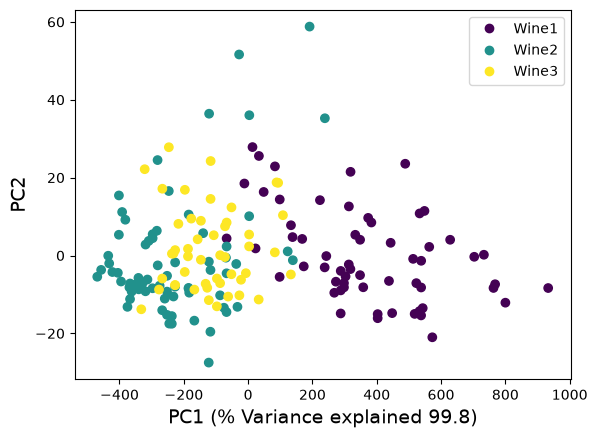

In [29]:
lot = plt.scatter(pca_2[:, 0], pca_2[:, 1], c=df.index)

plt.legend(
    handles=plot.legend_elements()[0],
    labels=['Wine1', 'Wine2', 'Wine3']
)

plt.xlabel("PC1 (% Variance explained 99.8)", fontsize=14)
plt.ylabel("PC2", fontsize=14)
plt.show()

We see some degree of clustering. But is there some way of making this better? Remember that the 13 variables are all measured in different scales.
What if we scale all the variables? Let us try that out now and repeat the above steps.

In [30]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()
df_scaled=scaler.fit_transform(df)
pca_3= pca.fit(df_scaled)

In [31]:
pca_3.explained_variance_ratio_

array([0.36198848, 0.1920749 , 0.11123631, 0.0706903 , 0.06563294,
       0.04935823, 0.04238679, 0.02680749, 0.02222153, 0.01930019,
       0.01736836, 0.01298233, 0.00795215])

In [32]:
pca_3.components_.shape

(13, 13)

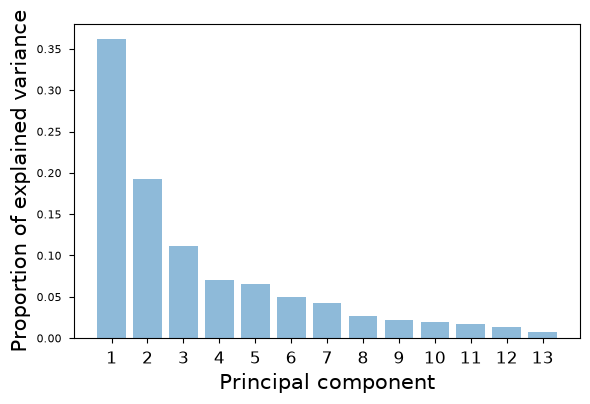

In [33]:
with plt.style.context('seaborn-v0_8-paper'):
    plt.figure(figsize=(6,4))

    plt.bar(range(13), pca_3.explained_variance_ratio_,alpha=0.5,align='center')
    plt.ylabel('Proportion of explained variance', fontsize=15)
    plt.xlabel('Principal component',fontsize=15)
    plt.xticks([0,1,2,3,4,5,6,7,8,9,10,11,12],["1","2","3","4","5","6","7","8","9","10","11","12","13"],fontsize=12)
    plt.tight_layout()

Following scaling, the overall variance in the dataset has been distributed across all the 13 components

In [34]:
wine_exp_var_2=pd.DataFrame(pca_3.explained_variance_ratio_,columns=["Proportion of variance explained"])
wine_exp_var_2.round(decimals=3)


,Proportion of variance explained
0,0.362
1,0.192
2,0.111
3,0.071
4,0.066
5,0.049
6,0.042
7,0.027
8,0.022
9,0.019


In [35]:
pca_4=pca.transform(df_scaled)

We are now ready to plot the results

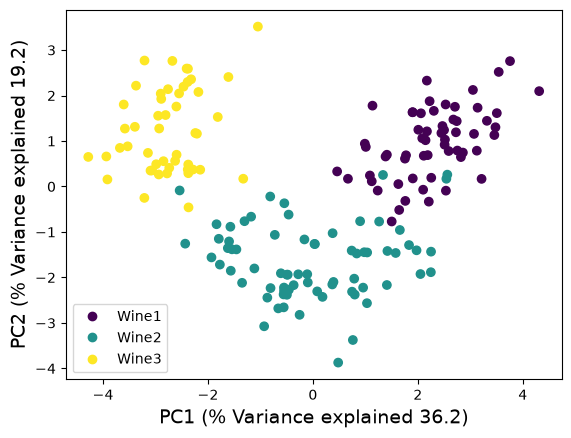

In [39]:
plot = plt.scatter(pca_4[:, 0], pca_4[:, 1], c=df.index)

plt.legend(
    handles=plot.legend_elements()[0],
    labels=['Wine1', 'Wine2', 'Wine3']
)

plt.xlabel(
    f"PC1 (% Variance explained {pca.explained_variance_ratio_[0]*100:.1f})",
    fontsize=14
)

plt.ylabel(
    f"PC2 (% Variance explained {pca.explained_variance_ratio_[1]*100:.1f})",
    fontsize=14
)
plt.show()

In [37]:
import numpy as np

np.allclose(pca_4[:, 1], -pca_2[:, 1])

False

In [38]:
np.allclose(pca_4[:, 0], pca_2[:, 0])

False

Thus we have been successful in achieving considerable seperation among the three different wines.
Therefore it is recommended to always scale the data while performing PCA.